In [1]:
#Entrenamiento de modelos de Machine Learning
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

# Modelos
from sklearn.dummy import DummyClassifier
from sklearn.linear_model import LogisticRegression
from sklearn.tree import DecisionTreeClassifier
from sklearn.ensemble import RandomForestClassifier

# Preprocesamiento, validación y clonación
from sklearn.preprocessing import StandardScaler
from sklearn.pipeline import Pipeline
from sklearn.model_selection import train_test_split, StratifiedKFold
from sklearn.base import clone

# Métricas
from sklearn.metrics import (accuracy_score, precision_score, recall_score,
                             f1_score, roc_auc_score)

# Persistencia
import joblib

# Configuración global
RANDOM_STATE = 42
np.random.seed(RANDOM_STATE)

plt.rcParams['figure.figsize'] = (12, 5)
plt.rcParams['font.size'] = 11
plt.rcParams['axes.spines.top'] = False
plt.rcParams['axes.spines.right'] = False

print("Librerías importadas correctamente")
print(f"   - numpy: {np.__version__}")
print(f"   - pandas: {pd.__version__}")
print(f"   - scikit-learn: {__import__('sklearn').__version__}")
print(f"\nSemilla de reproducibilidad: {RANDOM_STATE}")

Librerías importadas correctamente
   - numpy: 2.4.6
   - pandas: 2.2.3
   - scikit-learn: 1.6.1

Semilla de reproducibilidad: 42


In [2]:
#CELDA 2: Reconstruir dataset de Guía 8
# Mismas llamadas aleatorias y en el mismo orden que la Guía 8 (con semilla 42),
# para obtener exactamente los mismos 600 colaboradores.
n = 600

df_g8 = pd.DataFrame({"id_empleado": range(1, n + 1)})
df_g8["departamento"] = np.random.choice(["IT", "RRHH", "Finanzas", "Marketing", "Ventas"], n)
df_g8["edad"] = np.random.randint(21, 56, n)
df_g8["desempeño"] = np.random.normal(80, 9, n).clip(50, 100).round(0)
df_g8["salario"] = np.random.choice([550, 600, 650, 700, 750, 800, 900, 950], n)
df_g8["tiempo_empresa_anios"] = np.random.randint(0, 11, n)
df_g8["horas_capacitacion"] = np.random.choice([6, 8, 10, 12], n)
df_g8["satisfaccion"] = np.random.randint(1, 6, n)
df_g8["horas_extra"] = np.random.randint(0, 16, n)
df_g8["curso_aprobado"] = np.random.binomial(1, 0.75, n)

# Fórmula generadora (idéntica a Guía 8)
riesgo = (
    - 0.10 * (df_g8["desempeño"] - 80)
    - 0.45 * (df_g8["satisfaccion"] - 3)
    - 0.15 * (df_g8["horas_capacitacion"] - 9)
    + 0.06 * (df_g8["horas_extra"] - 7)
    - 0.60 * df_g8["curso_aprobado"]
    + np.random.normal(0, 0.8, n)
)
probabilidad = 1 / (1 + np.exp(-riesgo))
df_g8["requiere_capacitacion"] = np.random.binomial(1, probabilidad)

# One-Hot Encoding de departamento (idéntico a Guía 8)
df_modelo = pd.get_dummies(df_g8, columns=["departamento"], drop_first=True, dtype=int)

print(f"Dataset reconstruido: {df_modelo.shape[0]} filas, {df_modelo.shape[1]} columnas")
print(f"Colaboradores que requieren capacitación: {df_modelo['requiere_capacitacion'].mean()*100:.1f} %")
print(f"\nPrimeras 3 filas:")
print(df_modelo.head(3).to_string())

Dataset reconstruido: 600 filas, 14 columnas
Colaboradores que requieren capacitación: 42.2 %

Primeras 3 filas:
   id_empleado  edad  desempeño  salario  tiempo_empresa_anios  horas_capacitacion  satisfaccion  horas_extra  curso_aprobado  requiere_capacitacion  departamento_IT  departamento_Marketing  departamento_RRHH  departamento_Ventas
0            1    31       84.0      950                     2                  10             2            1               1                      1                0                       1                  0                    0
1            2    55       78.0      700                    10                   8             4           12               1                      0                0                       0                  0                    1
2            3    39       90.0      550                     7                  10             1           12               1                      0                0                       0        

In [3]:
#CELDA 3: Definir X, y y split 80/20 estratificado
features = [
    "edad", "desempeño", "salario", "tiempo_empresa_anios",
    "horas_capacitacion", "satisfaccion", "horas_extra", "curso_aprobado"
] + [c for c in df_modelo.columns if c.startswith("departamento_")]

X = df_modelo[features]
y = df_modelo["requiere_capacitacion"]

# Split 80/20 estratificado (mantiene la proporción de clases en train y test)
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.20, random_state=RANDOM_STATE, stratify=y
)

print("SPLIT 80/20 ESTRATIFICADO")
print("=" * 55)
print(f"Entrenamiento: {X_train.shape}")
print(f"Prueba:        {X_test.shape}")
print(f"\n% positivos en train: {y_train.mean()*100:.1f} %")
print(f"% positivos en test:  {y_test.mean()*100:.1f} %")

SPLIT 80/20 ESTRATIFICADO
Entrenamiento: (480, 12)
Prueba:        (120, 12)

% positivos en train: 42.1 %
% positivos en test:  42.5 %


In [4]:
#CELDA 4: Catálogo de modelos candidatos
modelos = {
    "Baseline clase frecuente": DummyClassifier(strategy="most_frequent"),
    "Regresión logística":      Pipeline([
                                    ("scaler", StandardScaler()),
                                    ("clf", LogisticRegression(random_state=RANDOM_STATE, max_iter=1000))
                                ]),
    "Árbol de decisión":        DecisionTreeClassifier(random_state=RANDOM_STATE),
    "Random Forest":            RandomForestClassifier(random_state=RANDOM_STATE)
}

print("MODELOS EN EL CATÁLOGO")
print("=" * 55)
for i, nombre in enumerate(modelos.keys(), 1):
    print(f"  {i}. {nombre}")

MODELOS EN EL CATÁLOGO
  1. Baseline clase frecuente
  2. Regresión logística
  3. Árbol de decisión
  4. Random Forest


In [5]:
#CELDA 5: Función de métricas y evaluación holdout
def metricas_clasificacion(modelo, X_, y_real):
    """Calcula Accuracy, Precision, Recall, F1 y ROC-AUC."""
    y_pred = modelo.predict(X_)
    y_prob = modelo.predict_proba(X_)[:, 1]
    return {
        "Accuracy":  accuracy_score(y_real, y_pred),
        "Precision": precision_score(y_real, y_pred, zero_division=0),
        "Recall":    recall_score(y_real, y_pred, zero_division=0),
        "F1":        f1_score(y_real, y_pred, zero_division=0),
        "ROC_AUC":   roc_auc_score(y_real, y_prob)
    }


def evaluar_holdout(nombre, estimador):
    """
    Entrena un modelo clonado, evalúa en train y test,
    y devuelve (modelo, fila_resultado, predicciones_test).
    """
    modelo = clone(estimador)
    modelo.fit(X_train, y_train)

    mt = metricas_clasificacion(modelo, X_train, y_train)
    mp = metricas_clasificacion(modelo, X_test,  y_test)

    fila = {
        "Modelo":     nombre,
        "F1_train":   mt["F1"],
        "Acc_test":   mp["Accuracy"],
        "Prec_test":  mp["Precision"],
        "Rec_test":   mp["Recall"],
        "F1_test":    mp["F1"],
        "AUC_test":   mp["ROC_AUC"],
        "Brecha_F1":  mt["F1"] - mp["F1"]     # train - test: si es grande, hay sobreajuste
    }

    return modelo, fila, modelo.predict(X_test)


print("Funciones definidas correctamente")

Funciones definidas correctamente


In [6]:
#CELDA 6: Entrenar y evaluar todos los modelos (holdout)
resultados_holdout = []
modelos_entrenados = {}
predicciones       = {}

for nombre, estimador in modelos.items():
    modelo, fila, pred = evaluar_holdout(nombre, estimador)
    modelos_entrenados[nombre] = modelo
    predicciones[nombre]       = pred
    resultados_holdout.append(fila)

tabla_holdout = pd.DataFrame(resultados_holdout)

print("RESULTADOS EN HOLDOUT (sin ordenar)")
print("=" * 95)
print(tabla_holdout.round(3).to_string(index=False))

RESULTADOS EN HOLDOUT (sin ordenar)
                  Modelo  F1_train  Acc_test  Prec_test  Rec_test  F1_test  AUC_test  Brecha_F1
Baseline clase frecuente     0.000     0.575      0.000     0.000    0.000     0.500      0.000
     Regresión logística     0.656     0.692      0.652     0.588    0.619     0.747      0.038
       Árbol de decisión     1.000     0.567      0.492     0.569    0.527     0.567      0.473
           Random Forest     1.000     0.708      0.667     0.627    0.646     0.743      0.354


In [7]:
#CELDA 7: Ordenar por F1_test y mejora vs baseline
f1_baseline = tabla_holdout.loc[
    tabla_holdout["Modelo"] == "Baseline clase frecuente", "F1_test"
].iloc[0]

# El baseline suele tener F1 = 0, así que la mejora se mide en puntos, no en %
tabla_holdout["Mejora_F1_vs_baseline"] = tabla_holdout["F1_test"] - f1_baseline

tabla_holdout = tabla_holdout.sort_values("F1_test", ascending=False).reset_index(drop=True)

print(f"F1 del baseline: {f1_baseline:.3f}")
print("\nTABLA COMPARATIVA (ordenada por F1_test)")
print("=" * 105)
print(tabla_holdout.round(3).to_string(index=False))

F1 del baseline: 0.000

TABLA COMPARATIVA (ordenada por F1_test)
                  Modelo  F1_train  Acc_test  Prec_test  Rec_test  F1_test  AUC_test  Brecha_F1  Mejora_F1_vs_baseline
           Random Forest     1.000     0.708      0.667     0.627    0.646     0.743      0.354                  0.646
     Regresión logística     0.656     0.692      0.652     0.588    0.619     0.747      0.038                  0.619
       Árbol de decisión     1.000     0.567      0.492     0.569    0.527     0.567      0.473                  0.527
Baseline clase frecuente     0.000     0.575      0.000     0.000    0.000     0.500      0.000                  0.000


In [8]:
#CELDA 8: Diagnóstico de sobreajuste (brecha train/test)
print("DIAGNÓSTICO DE SOBREAJUSTE")
print("=" * 75)

for _, row in tabla_holdout.iterrows():
    nombre = row["Modelo"]
    brecha = row["Brecha_F1"]
    f1_tr  = row["F1_train"]

    if f1_tr >= 0.99 and brecha > 0.15:
        señal = "(ROJO) Posible sobreajuste severo (F1_train ≈ 1)"
    elif brecha > 0.10:
        señal = "(NARANJA) Posible sobreajuste (brecha F1 > 0.10)"
    elif brecha < 0:
        señal = "(AMARILLO) Brecha negativa (test más fácil que train)"
    else:
        señal = "(VERDE) Brecha razonable"

    print(f"\n{nombre}")
    print(f"   F1_train: {f1_tr:>6.3f}")
    print(f"   F1_test:  {row['F1_test']:>6.3f}")
    print(f"   Brecha:   {brecha:>6.3f}")
    print(f"   → {señal}")

DIAGNÓSTICO DE SOBREAJUSTE

Random Forest
   F1_train:  1.000
   F1_test:   0.646
   Brecha:    0.354
   → (ROJO) Posible sobreajuste severo (F1_train ≈ 1)

Regresión logística
   F1_train:  0.656
   F1_test:   0.619
   Brecha:    0.038
   → (VERDE) Brecha razonable

Árbol de decisión
   F1_train:  1.000
   F1_test:   0.527
   Brecha:    0.473
   → (ROJO) Posible sobreajuste severo (F1_train ≈ 1)

Baseline clase frecuente
   F1_train:  0.000
   F1_test:   0.000
   Brecha:    0.000
   → (VERDE) Brecha razonable


In [9]:
#CELDA 9: Crear StratifiedKFold y visualizar folds
# No hay fechas en el dataset, así que se usa validación cruzada estratificada
# (con mezcla) en lugar de TimeSeriesSplit.
skf = StratifiedKFold(n_splits=5, shuffle=True, random_state=RANDOM_STATE)

print("FOLDS DE VALIDACIÓN CRUZADA ESTRATIFICADA")
print("=" * 75)
print(f"{'Fold':<6}{'Filas train':<14}{'Filas val':<14}{'% positivos train':<20}{'% positivos val':<16}")

for fold, (idx_tr, idx_val) in enumerate(skf.split(X_train, y_train), 1):
    print(
        f"{fold:<6}"
        f"{len(idx_tr):<14}"
        f"{len(idx_val):<14}"
        f"{y_train.iloc[idx_tr].mean()*100:<20.1f}"
        f"{y_train.iloc[idx_val].mean()*100:<16.1f}"
    )

print(f"\nTotal de filas en X_train: {len(X_train)}")
print(f"Filas por fold de validación: ~{len(X_train) // skf.get_n_splits()}")

FOLDS DE VALIDACIÓN CRUZADA ESTRATIFICADA
Fold  Filas train   Filas val     % positivos train   % positivos val 
1     384           96            41.9                42.7            
2     384           96            41.9                42.7            
3     384           96            42.2                41.7            
4     384           96            42.2                41.7            
5     384           96            42.2                41.7            

Total de filas en X_train: 480
Filas por fold de validación: ~96


In [10]:
#CELDA 10: Función de validación cruzada
def validar_cruzada(nombre, estimador):
    """Aplica StratifiedKFold a un estimador y devuelve métricas por fold."""
    filas = []

    for fold, (idx_tr, idx_val) in enumerate(skf.split(X_train, y_train), 1):
        X_tr,  X_val = X_train.iloc[idx_tr], X_train.iloc[idx_val]
        y_tr,  y_val = y_train.iloc[idx_tr], y_train.iloc[idx_val]

        m = clone(estimador)
        m.fit(X_tr, y_tr)

        pred_tr  = m.predict(X_tr)
        pred_val = m.predict(X_val)
        prob_val = m.predict_proba(X_val)[:, 1]

        filas.append({
            "Modelo":   nombre,
            "Fold":     fold,
            "F1_train": f1_score(y_tr,  pred_tr,  zero_division=0),
            "F1_val":   f1_score(y_val, pred_val, zero_division=0),
            "Acc_val":  accuracy_score(y_val, pred_val),
            "AUC_val":  roc_auc_score(y_val, prob_val)
        })

    return pd.DataFrame(filas)


print("Función 'validar_cruzada' definida correctamente")

Función 'validar_cruzada' definida correctamente


In [11]:
#CELDA 11: Ejecutar validación cruzada
validaciones = []
for nombre, estimador in modelos.items():
    validaciones.append(validar_cruzada(nombre, estimador))

df_cv = pd.concat(validaciones, ignore_index=True)

print("DETALLE DE VALIDACIÓN CRUZADA")
print("=" * 75)
print(df_cv.round(3).to_string(index=False))

DETALLE DE VALIDACIÓN CRUZADA
                  Modelo  Fold  F1_train  F1_val  Acc_val  AUC_val
Baseline clase frecuente     1     0.000   0.000    0.573    0.500
Baseline clase frecuente     2     0.000   0.000    0.573    0.500
Baseline clase frecuente     3     0.000   0.000    0.583    0.500
Baseline clase frecuente     4     0.000   0.000    0.583    0.500
Baseline clase frecuente     5     0.000   0.000    0.583    0.500
     Regresión logística     1     0.647   0.648    0.740    0.795
     Regresión logística     2     0.667   0.649    0.729    0.727
     Regresión logística     3     0.662   0.585    0.646    0.699
     Regresión logística     4     0.654   0.690    0.729    0.818
     Regresión logística     5     0.667   0.568    0.667    0.732
       Árbol de decisión     1     1.000   0.596    0.604    0.614
       Árbol de decisión     2     1.000   0.532    0.615    0.602
       Árbol de decisión     3     1.000   0.500    0.562    0.557
       Árbol de decisión     4  

In [12]:
#CELDA 12: Resumen por modelo (media y std)
resumen_cv = (
    df_cv
    .groupby("Modelo")
    .agg(
        F1_cv_media   = ("F1_val",  "mean"),
        F1_cv_std     = ("F1_val",  "std"),
        Acc_cv_media  = ("Acc_val", "mean"),
        AUC_cv_media  = ("AUC_val", "mean")
    )
    .reset_index()
    .sort_values("F1_cv_media", ascending=False)
    .reset_index(drop=True)
)

print("RESUMEN DE VALIDACIÓN CRUZADA")
print("=" * 85)
print(resumen_cv.round(3).to_string(index=False))

RESUMEN DE VALIDACIÓN CRUZADA
                  Modelo  F1_cv_media  F1_cv_std  Acc_cv_media  AUC_cv_media
     Regresión logística        0.628      0.050         0.702         0.754
           Random Forest        0.565      0.066         0.669         0.703
       Árbol de decisión        0.540      0.040         0.600         0.594
Baseline clase frecuente        0.000      0.000         0.579         0.500


In [13]:
#CELDA 13: Integrar holdout + CV y marcar candidatos
comparacion = tabla_holdout.merge(resumen_cv, on="Modelo", how="left")
comparacion = comparacion.sort_values("F1_test", ascending=False).reset_index(drop=True)

# Criterios de selección
comparacion["Supera_baseline"] = comparacion["Mejora_F1_vs_baseline"] > 0
comparacion["CV_estable"]      = (
    comparacion["F1_cv_std"] < comparacion["F1_cv_media"] * 0.25
)

columnas_mostrar = [
    "Modelo", "F1_test", "AUC_test", "Mejora_F1_vs_baseline",
    "F1_cv_media", "F1_cv_std", "Brecha_F1",
    "Supera_baseline", "CV_estable"
]

print("TABLA COMPARATIVA INTEGRADA")
print("=" * 110)
print(comparacion[columnas_mostrar].round(3).to_string(index=False))

TABLA COMPARATIVA INTEGRADA
                  Modelo  F1_test  AUC_test  Mejora_F1_vs_baseline  F1_cv_media  F1_cv_std  Brecha_F1  Supera_baseline  CV_estable
           Random Forest    0.646     0.743                  0.646        0.565      0.066      0.354             True        True
     Regresión logística    0.619     0.747                  0.619        0.628      0.050      0.038             True        True
       Árbol de decisión    0.527     0.567                  0.527        0.540      0.040      0.473             True        True
Baseline clase frecuente    0.000     0.500                  0.000        0.000      0.000      0.000            False       False


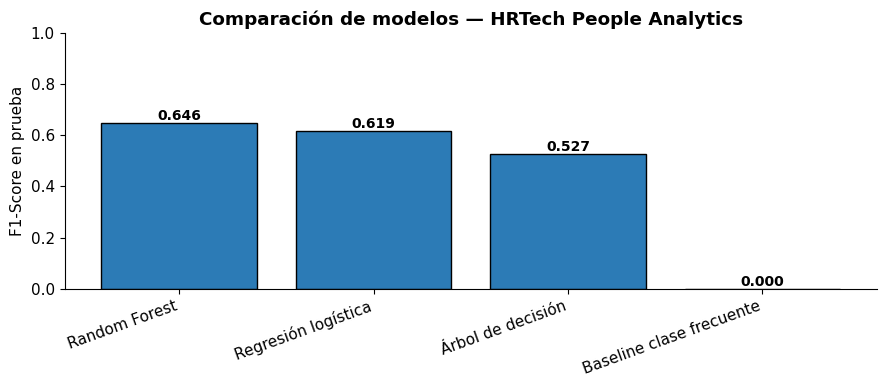

In [14]:
#CELDA 14: Gráfico de barras F1_test por modelo
graf = comparacion.sort_values("F1_test", ascending=False)

fig, ax = plt.subplots(figsize=(9, 4))
colores = ['#4781AD' if m == "Baseline clase frecuente" else '#2c7bb6'
           for m in graf["Modelo"]]

bars = ax.bar(graf["Modelo"], graf["F1_test"], color=colores, edgecolor='black')

# Etiquetas de valor sobre cada barra
for bar, val in zip(bars, graf["F1_test"]):
    ax.text(bar.get_x() + bar.get_width() / 2, bar.get_height(),
            f"{val:.3f}", ha='center', va='bottom', fontsize=10, fontweight='bold')

ax.set_ylabel("F1-Score en prueba")
ax.set_ylim(0, 1)
ax.set_title("Comparación de modelos — HRTech People Analytics", fontweight='bold')
plt.xticks(rotation=20, ha='right')
plt.tight_layout()
plt.show()

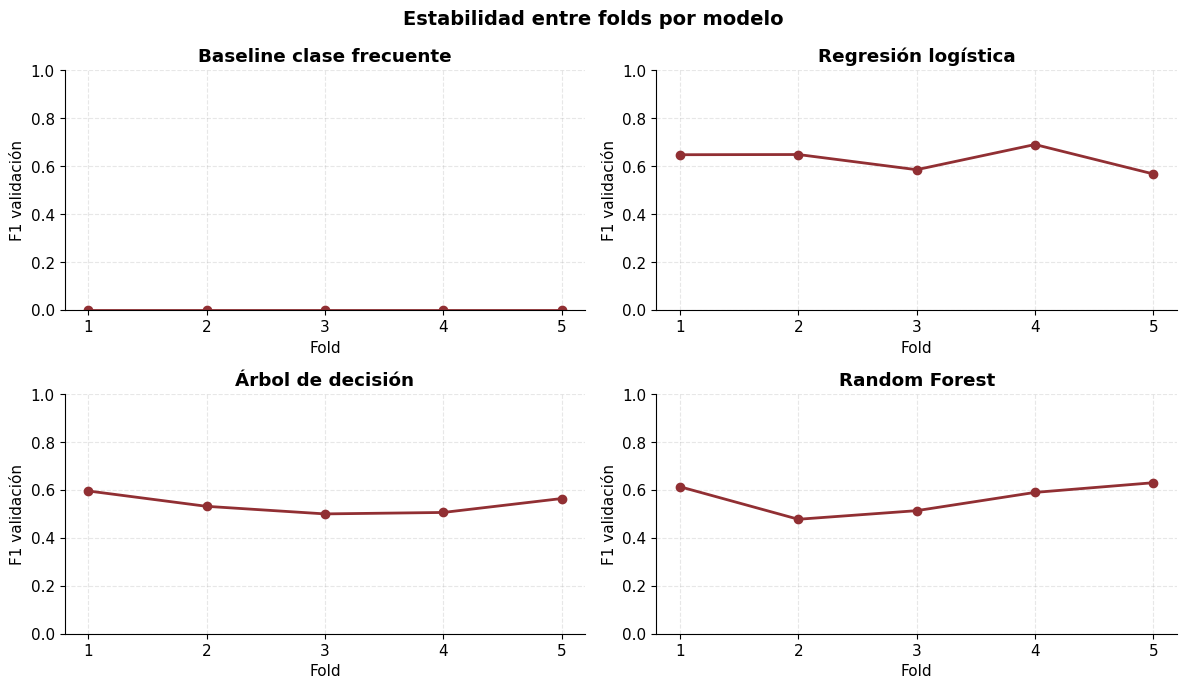

In [15]:
#CELDA 15: Estabilidad entre folds (una gráfica por modelo)
fig, axes = plt.subplots(2, 2, figsize=(12, 7))
axes = axes.flatten()

for i, nombre in enumerate(df_cv["Modelo"].unique()):
    temp = df_cv[df_cv["Modelo"] == nombre]
    axes[i].plot(temp["Fold"], temp["F1_val"],
                 marker='o', linewidth=2, color='#912F33')
    axes[i].set_title(nombre, fontweight='bold')
    axes[i].set_xlabel("Fold")
    axes[i].set_ylabel("F1 validación")
    axes[i].set_ylim(0, 1)
    axes[i].grid(alpha=0.3, linestyle='--')
    axes[i].set_xticks(temp["Fold"].tolist())

plt.suptitle("Estabilidad entre folds por modelo", fontsize=14, fontweight='bold')
plt.tight_layout()
plt.show()

In [16]:
#CELDA 16: Seleccionar candidato provisional
candidatos = comparacion[comparacion["Supera_baseline"]].copy()

# Se ordena por F1_test y, en caso de empate, por AUC_test
candidato_ordenado = candidatos.sort_values(["F1_test", "AUC_test"], ascending=False)

nombre_candidato = candidato_ordenado.iloc[0]["Modelo"]
modelo_candidato = modelos_entrenados[nombre_candidato]
pred_candidato   = predicciones[nombre_candidato]
prob_candidato   = modelo_candidato.predict_proba(X_test)[:, 1]

print("CANDIDATO PROVISIONAL")
print("=" * 55)
print(f"  Modelo: {nombre_candidato}")
print(f"  F1_test:        {candidato_ordenado.iloc[0]['F1_test']:.3f}")
print(f"  Accuracy_test:  {candidato_ordenado.iloc[0]['Acc_test']:.3f}")
print(f"  Precision_test: {candidato_ordenado.iloc[0]['Prec_test']:.3f}")
print(f"  Recall_test:    {candidato_ordenado.iloc[0]['Rec_test']:.3f}")
print(f"  ROC-AUC_test:   {candidato_ordenado.iloc[0]['AUC_test']:.3f}")
print(f"  Mejora F1 vs baseline: {candidato_ordenado.iloc[0]['Mejora_F1_vs_baseline']:+.3f} puntos")

print(f"\nModelos que superan al baseline:")
for _, row in candidato_ordenado.iterrows():
    print(f"  - {row['Modelo']}: F1 = {row['F1_test']:.3f}")

CANDIDATO PROVISIONAL
  Modelo: Random Forest
  F1_test:        0.646
  Accuracy_test:  0.708
  Precision_test: 0.667
  Recall_test:    0.627
  ROC-AUC_test:   0.743
  Mejora F1 vs baseline: +0.646 puntos

Modelos que superan al baseline:
  - Random Forest: F1 = 0.646
  - Regresión logística: F1 = 0.619
  - Árbol de decisión: F1 = 0.527


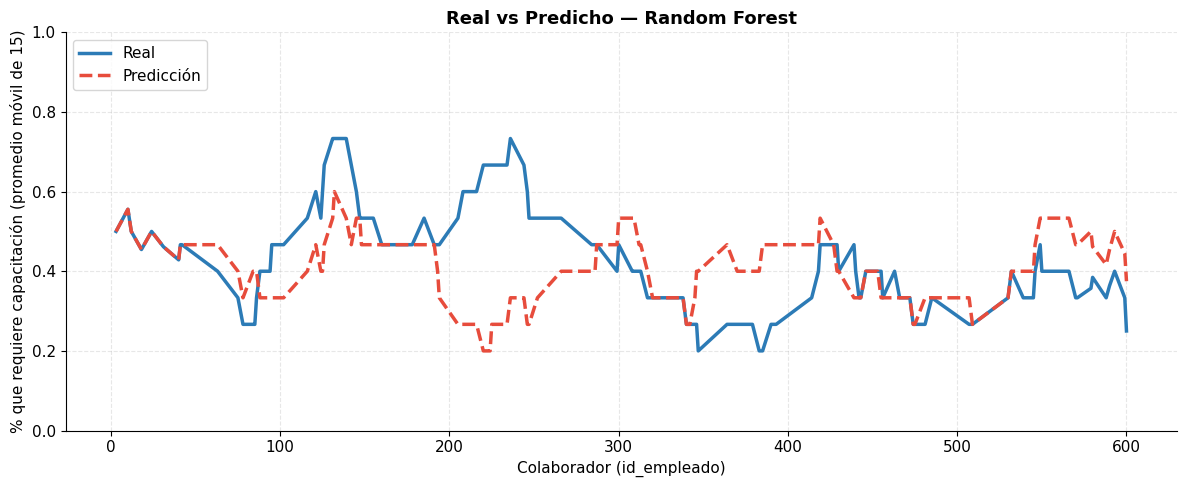

In [17]:
#CELDA 17: Gráfico Real vs Predicho del candidato

VENTANA  = 15
ids_test = df_modelo.loc[X_test.index, "id_empleado"].values
orden    = np.argsort(ids_test)

real_mov = pd.Series(y_test.values[orden]).rolling(VENTANA, center=True, min_periods=1).mean()
pred_mov = pd.Series(pred_candidato[orden]).rolling(VENTANA, center=True, min_periods=1).mean()

fig, ax = plt.subplots(figsize=(12, 5))

ax.plot(ids_test[orden], real_mov, label="Real",
        color='#2c7bb6', linewidth=2.5)
ax.plot(ids_test[orden], pred_mov, label="Predicción",
        color='#e74c3c', linewidth=2.5, linestyle='--')

ax.set_title(f"Real vs Predicho — {nombre_candidato}",
             fontsize=13, fontweight='bold')
ax.set_xlabel("Colaborador (id_empleado)")
ax.set_ylabel(f"% que requiere capacitación (promedio móvil de {VENTANA})")
ax.set_ylim(0, 1)
ax.legend(loc='upper left')
ax.grid(alpha=0.3, linestyle='--')
plt.tight_layout()
plt.show()

In [18]:
#CELDA 18: Top 5 errores más graves del candidato
errores = pd.DataFrame({
    "id_empleado":  df_modelo.loc[X_test.index, "id_empleado"].values,
    "real":         y_test.values,
    "predicho":     pred_candidato,
    "probabilidad": prob_candidato.round(3)
})

errores["acierto"]   = errores["real"] == errores["predicho"]
errores["tipo_error"] = np.where(
    errores["acierto"], "Acierto",
    np.where(errores["real"] == 1, "FN (no detectado)", "FP (falsa alarma)")
)

# Gravedad = qué tan seguro estaba el modelo en su equivocación
errores["error_abs"] = (errores["real"] - errores["probabilidad"]).abs().round(3)

solo_errores = errores[~errores["acierto"]]

print("ESTADÍSTICAS DE ERROR")
print("=" * 55)
print(f"  Total de errores:         {len(solo_errores)} de {len(errores)} ({len(solo_errores)/len(errores)*100:.1f} %)")
print(f"  Falsos positivos (FP):    {(solo_errores['tipo_error'] == 'FP (falsa alarma)').sum()}")
print(f"  Falsos negativos (FN):    {(solo_errores['tipo_error'] == 'FN (no detectado)').sum()}")
print(f"  Error absoluto promedio:  {errores['error_abs'].mean():.3f}")

print(f"\nTOP 5 ERRORES MÁS GRAVES")
print("=" * 75)
print(solo_errores.nlargest(5, "error_abs").to_string(index=False))

print("\nNOTA: un FN es el error más costoso en este proyecto (un colaborador que necesita")
print("      capacitación y no fue detectado). Datos sintéticos: no usar para decisiones reales.")

ESTADÍSTICAS DE ERROR
  Total de errores:         35 de 120 (29.2 %)
  Falsos positivos (FP):    16
  Falsos negativos (FN):    19
  Error absoluto promedio:  0.413

TOP 5 ERRORES MÁS GRAVES
 id_empleado  real  predicho  probabilidad  acierto        tipo_error  error_abs
         220     1         0          0.17    False FN (no detectado)       0.83
         131     1         0          0.20    False FN (no detectado)       0.80
         390     0         1          0.79    False FP (falsa alarma)       0.79
         234     1         0          0.25    False FN (no detectado)       0.75
         507     1         0          0.29    False FN (no detectado)       0.71

NOTA: un FN es el error más costoso en este proyecto (un colaborador que necesita
      capacitación y no fue detectado). Datos sintéticos: no usar para decisiones reales.


In [19]:
# Interpretación de variables del candidato
# Si el modelo es un Pipeline (ej. regresión logística con StandardScaler),
estimador_final = (modelo_candidato.steps[-1][1]
                   if isinstance(modelo_candidato, Pipeline) else modelo_candidato)

if hasattr(estimador_final, "coef_"):
    importancia = pd.DataFrame({
        "variable":   features,
        "valor":      estimador_final.coef_[0],
        "odds_ratio": np.exp(estimador_final.coef_[0])
    }).sort_values("valor", key=lambda s: s.abs(), ascending=False)

    print(f"COEFICIENTES — {nombre_candidato} (variables estandarizadas)")
    print("=" * 65)
    print(importancia.round(4).to_string(index=False))
    print(f"\nIntercepto: {estimador_final.intercept_[0]:.4f}")
    print("Coeficiente > 0: aumenta la probabilidad de requerir capacitación")
    print("Coeficiente < 0: la disminuye")

elif hasattr(estimador_final, "feature_importances_"):
    importancia = pd.DataFrame({
        "variable": features,
        "valor":    estimador_final.feature_importances_
    }).sort_values("valor", ascending=False)

    print(f"FEATURE IMPORTANCE — {nombre_candidato}")
    print("=" * 65)
    print(importancia.round(4).to_string(index=False))
    print(f"\nSuma de importancias: {importancia['valor'].sum():.4f}")
    print("NOTA: la importancia indica cuánto usa el modelo cada variable,")
    print("      no la dirección del efecto (no dice si sube o baja el riesgo).")

else:
    importancia = pd.DataFrame()
    print("El modelo no expone coeficientes ni importancias.")


FEATURE IMPORTANCE — Random Forest
              variable  valor
             desempeño 0.2227
           horas_extra 0.1420
                  edad 0.1368
          satisfaccion 0.1105
  tiempo_empresa_anios 0.1067
               salario 0.0938
    horas_capacitacion 0.0704
        curso_aprobado 0.0275
   departamento_Ventas 0.0233
       departamento_IT 0.0232
departamento_Marketing 0.0221
     departamento_RRHH 0.0211

Suma de importancias: 1.0000
NOTA: la importancia indica cuánto usa el modelo cada variable,
      no la dirección del efecto (no dice si sube o baja el riesgo).


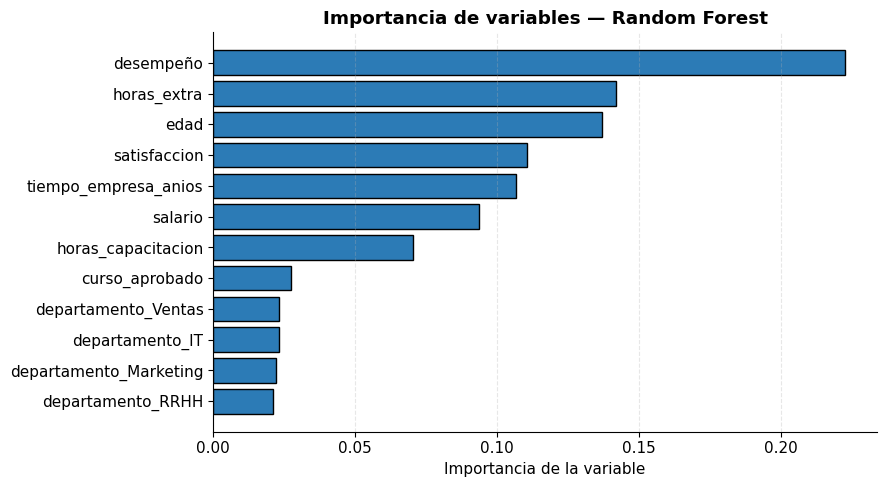

In [20]:
# Gráfico de importancia de variables
if not importancia.empty:
    graf_imp = importancia.sort_values("valor", key=lambda s: s.abs(), ascending=True)

    fig, ax = plt.subplots(figsize=(9, 5))

    if "odds_ratio" in graf_imp.columns:
        # Regresión logística: el signo importa (rojo = sube el riesgo, azul = lo baja)
        colores = ['#912F33' if v > 0 else '#2c7bb6' for v in graf_imp["valor"]]
        ax.barh(graf_imp["variable"], graf_imp["valor"], color=colores, edgecolor='black')
        ax.axvline(0, color='black', linewidth=0.8)
        ax.set_xlabel("Coeficiente (rojo: aumenta el riesgo | azul: lo reduce)")
    else:
        # Random Forest / Árbol: solo magnitud
        ax.barh(graf_imp["variable"], graf_imp["valor"].abs(),
                color='#2c7bb6', edgecolor='black')
        ax.set_xlabel("Importancia de la variable")

    ax.set_title(f"Importancia de variables — {nombre_candidato}", fontweight='bold')
    ax.grid(alpha=0.3, axis='x', linestyle='--')
    plt.tight_layout()
    plt.show()
else:
    print("Sin datos de importancia para graficar.")

In [21]:
# Matriz de decisión técnica
import time

fila_c = candidato_ordenado.iloc[0]

# Costo: tiempo real de entrenamiento del candidato
t0 = time.perf_counter()
clone(modelos[nombre_candidato]).fit(X_train, y_train)
tiempo_fit = time.perf_counter() - t0

# Riesgo: FN = colaborador que necesita capacitación y no fue detectado
n_fn = int((solo_errores["tipo_error"] == "FN (no detectado)").sum())
n_pos_test = int(y_test.sum())

def semaforo(cond_verde, cond_amarillo):
    return "VERDE" if cond_verde else ("AMARILLO" if cond_amarillo else "ROJO")

matriz = pd.DataFrame({
    "Criterio": ["Desempeño", "Generalización", "Estabilidad",
                 "Interpretabilidad", "Costo", "Riesgo"],
    "Pregunta": [
        "¿Supera claramente al baseline?",
        "¿La brecha train/test es razonable?",
        "¿Los folds son consistentes?",
        "¿Podemos explicar la salida?",
        "¿Tiempo y recursos adecuados?",
        "¿Errores graves en escenarios críticos?"
    ],
    "Valor observado": [
        f"F1 {fila_c['F1_test']:.3f} (+{fila_c['Mejora_F1_vs_baseline']:.3f} vs baseline), AUC {fila_c['AUC_test']:.3f}",
        f"Brecha F1 = {fila_c['Brecha_F1']:.3f}",
        f"F1 CV = {fila_c['F1_cv_media']:.3f} ± {fila_c['F1_cv_std']:.3f}",
        "Coeficientes (con signo)" if hasattr(estimador_final, "coef_") else "Feature importances (sin signo)",
        f"{tiempo_fit:.2f} s de entrenamiento",
        f"{n_fn} FN de {n_pos_test} que sí requerían capacitación (Recall {fila_c['Rec_test']:.3f})"
    ],
    "Semáforo": [
        semaforo(fila_c["AUC_test"] >= 0.70, fila_c["AUC_test"] >= 0.60),
        semaforo(fila_c["Brecha_F1"] <= 0.10, fila_c["Brecha_F1"] <= 0.20),
        semaforo(fila_c["F1_cv_std"] < fila_c["F1_cv_media"] * 0.10,
                 fila_c["F1_cv_std"] < fila_c["F1_cv_media"] * 0.25),
        "VERDE" if hasattr(estimador_final, "coef_") else "AMARILLO",
        semaforo(tiempo_fit < 1, tiempo_fit < 10),
        semaforo(fila_c["Rec_test"] >= 0.80, fila_c["Rec_test"] >= 0.60)
    ]
})

print("MATRIZ DE DECISIÓN TÉCNICA")
print("=" * 110)
print(matriz.to_string(index=False))

# Contraste con el modelo más estable en validación cruzada
mejor_cv = resumen_cv[resumen_cv["Modelo"] != "Baseline clase frecuente"].iloc[0]
print("\nCONTRASTE CON LA VALIDACIÓN CRUZADA")
print("=" * 110)
print(f"  Candidato por F1_test:           {nombre_candidato} (F1_cv = {fila_c['F1_cv_media']:.3f})")
print(f"  Mejor modelo por F1_cv_media:    {mejor_cv['Modelo']} (F1_cv = {mejor_cv['F1_cv_media']:.3f}, AUC_cv = {mejor_cv['AUC_cv_media']:.3f})")
if mejor_cv["Modelo"] != nombre_candidato:
    print("  → El candidato no es el mejor en validación cruzada: la ventaja en test puede ser")
    print("    ruido de un solo split de 120 filas. Se mantiene como candidato PROVISIONAL y se")
    print("    comparan ambos con hiperparámetros ajustados en la Guía 10.")

MATRIZ DE DECISIÓN TÉCNICA
         Criterio                                Pregunta                                          Valor observado Semáforo
        Desempeño         ¿Supera claramente al baseline?                 F1 0.646 (+0.646 vs baseline), AUC 0.743    VERDE
   Generalización     ¿La brecha train/test es razonable?                                        Brecha F1 = 0.354     ROJO
      Estabilidad            ¿Los folds son consistentes?                                    F1 CV = 0.565 ± 0.066 AMARILLO
Interpretabilidad            ¿Podemos explicar la salida?                          Feature importances (sin signo) AMARILLO
            Costo           ¿Tiempo y recursos adecuados?                                  1.13 s de entrenamiento AMARILLO
           Riesgo ¿Errores graves en escenarios críticos? 19 FN de 51 que sí requerían capacitación (Recall 0.627) AMARILLO

CONTRASTE CON LA VALIDACIÓN CRUZADA
  Candidato por F1_test:           Random Forest (F1_cv = 0.565)
  M

In [22]:
#CELDA 22: Crear estructura de carpetas
from pathlib import Path

BASE = Path('/content/')
(BASE / 'datos' / 'procesados').mkdir(parents=True, exist_ok=True)
(BASE / 'documentos').mkdir(parents=True, exist_ok=True)
(BASE / 'modelos').mkdir(parents=True, exist_ok=True)

print(f"Estructura creada en: {BASE}")
print(f"  - datos/procesados/")
print(f"  - documentos/")
print(f"  - modelos/")

Estructura creada en: /content
  - datos/procesados/
  - documentos/
  - modelos/


In [23]:
# Exportar artefactos reproducibles

# 1) Tabla comparativa completa (holdout + CV)
ruta_comparacion = BASE / 'documentos' / 'comparacion_modelos_guia09_hrtech.csv'
comparacion.to_csv(ruta_comparacion, index=False, encoding='utf-8')

# 2) Detalle de validación cruzada
ruta_cv = BASE / 'documentos' / 'validacion_cruzada_guia09_hrtech.csv'
df_cv.to_csv(ruta_cv, index=False, encoding='utf-8')

# 3) Matriz de decisión técnica
ruta_matriz = BASE / 'documentos' / 'matriz_decision_guia09_hrtech.csv'
matriz.to_csv(ruta_matriz, index=False, encoding='utf-8')

# 4) Predicciones del candidato sobre el conjunto de prueba
ruta_pred = BASE / 'datos' / 'procesados' / 'predicciones_guia09_hrtech.csv'
errores.to_csv(ruta_pred, index=False, encoding='utf-8')

# 5) Modelo candidato persistido
ruta_modelo = BASE / 'modelos' / 'modelo_candidato_guia09_hrtech.joblib'
joblib.dump(modelo_candidato, ruta_modelo)

print("ARTEFACTOS EXPORTADOS")
print("=" * 75)
for r in [ruta_comparacion, ruta_cv, ruta_matriz, ruta_pred, ruta_modelo]:
    print(f"  {r.name}  ({r.stat().st_size / 1024:.1f} KB)")

ARTEFACTOS EXPORTADOS
  comparacion_modelos_guia09_hrtech.csv  (1.0 KB)
  validacion_cruzada_guia09_hrtech.csv  (1.5 KB)
  matriz_decision_guia09_hrtech.csv  (0.6 KB)
  predicciones_guia09_hrtech.csv  (4.0 KB)
  modelo_candidato_guia09_hrtech.joblib  (1925.1 KB)


In [24]:
# Registrar versiones y metadata
import sklearn
import sys
from datetime import datetime

metadata = {
    "fecha_ejecucion":  datetime.now().isoformat(),
    "python":           sys.version.split()[0],
    "scikit_learn":     sklearn.__version__,
    "pandas":           pd.__version__,
    "numpy":            np.__version__,
    "random_state":     RANDOM_STATE,
    "n_filas":          len(df_modelo),
    "n_train":          len(X_train),
    "n_test":           len(X_test),
    "n_features":       len(features),
    "validacion":       "StratifiedKFold(n_splits=5, shuffle=True)",
    "metrica_seleccion": "F1_test",
    "modelo_candidato": nombre_candidato,
    "F1_test":          round(float(fila_c["F1_test"]), 4),
    "AUC_test":         round(float(fila_c["AUC_test"]), 4),
    "F1_cv_media":      round(float(fila_c["F1_cv_media"]), 4)
}

ruta_meta = BASE / 'documentos' / 'metadata_guia09_hrtech.csv'
pd.DataFrame([metadata]).to_csv(ruta_meta, index=False, encoding='utf-8')

print("METADATA DEL EXPERIMENTO")
print("=" * 75)
for k, v in metadata.items():
    print(f"  {k}: {v}")
print(f"\nGuardado en: {ruta_meta.name}")

METADATA DEL EXPERIMENTO
  fecha_ejecucion: 2026-11-18T02:33:34.001856
  python: 3.13.18
  scikit_learn: 1.6.1
  pandas: 2.2.3
  numpy: 2.4.6
  random_state: 42
  n_filas: 600
  n_train: 480
  n_test: 120
  n_features: 12
  validacion: StratifiedKFold(n_splits=5, shuffle=True)
  metrica_seleccion: F1_test
  modelo_candidato: Random Forest
  F1_test: 0.6465
  AUC_test: 0.7433
  F1_cv_media: 0.5649

Guardado en: metadata_guia09_hrtech.csv


In [25]:
# Descargar artefactos desde Colab
try:
    from google.colab import files

    archivos = [ruta_comparacion, ruta_cv, ruta_matriz, ruta_pred, ruta_modelo, ruta_meta]
    for r in archivos:
        files.download(str(r))

    print(f"Descarga iniciada para {len(archivos)} archivos")
except ImportError:
    print("No se está ejecutando en Google Colab: los archivos quedan en las carpetas del proyecto.")

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

... (3 outputs left out)

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

Descarga iniciada para 6 archivos


In [26]:
# Resumen ejecutivo del experimento
print("=" * 75)
print("RESUMEN EJECUTIVO — GUÍA 9 — HRTECH PEOPLE ANALYTICS")
print("=" * 75)

print(f"\nPROBLEMA: clasificar si un colaborador requiere capacitación (1) o no (0)")
print(f"DATOS:    {len(df_modelo)} colaboradores sintéticos | {len(features)} variables | "
      f"train {len(X_train)} / test {len(X_test)}")

print(f"\nMODELOS EVALUADOS: {len(modelos)}")
for nombre in modelos.keys():
    print(f"   • {nombre}")

print(f"\nMODELO CANDIDATO (PROVISIONAL): {nombre_candidato}")
print(f"   F1_test:             {fila_c['F1_test']:.3f}")
print(f"   Accuracy_test:       {fila_c['Acc_test']:.3f}")
print(f"   Precision / Recall:  {fila_c['Prec_test']:.3f} / {fila_c['Rec_test']:.3f}")
print(f"   ROC-AUC_test:        {fila_c['AUC_test']:.3f}")
print(f"   Mejora F1 vs baseline: {fila_c['Mejora_F1_vs_baseline']:+.3f} puntos")
print(f"   F1 en CV (media±std):  {fila_c['F1_cv_media']:.3f} ± {fila_c['F1_cv_std']:.3f}")
print(f"   Brecha F1 train-test:  {fila_c['Brecha_F1']:.3f}")

print(f"\nVARIABLES MÁS INFLUYENTES:")
for _, r in importancia.head(3).iterrows():
    print(f"   • {r['variable']}")

print(f"\nLIMITACIONES:")
print(f"   • Datos sintéticos: los resultados no sirven para decisiones reales")
print(f"   • Un solo split de {len(X_test)} filas: las métricas de test tienen mucha varianza")
print(f"   • Modelo sin ajustar hiperparámetros (valores por defecto)")

print(f"\nARTEFACTOS GENERADOS:")
for r in [ruta_comparacion, ruta_cv, ruta_matriz, ruta_pred, ruta_modelo, ruta_meta]:
    print(f"   • {r.name}")

print(f"\nSIGUIENTE PASO (Guía 10): optimizar hiperparámetros")
print("=" * 75)

RESUMEN EJECUTIVO — GUÍA 9 — HRTECH PEOPLE ANALYTICS

PROBLEMA: clasificar si un colaborador requiere capacitación (1) o no (0)
DATOS:    600 colaboradores sintéticos | 12 variables | train 480 / test 120

MODELOS EVALUADOS: 4
   • Baseline clase frecuente
   • Regresión logística
   • Árbol de decisión
   • Random Forest

MODELO CANDIDATO (PROVISIONAL): Random Forest
   F1_test:             0.646
   Accuracy_test:       0.708
   Precision / Recall:  0.667 / 0.627
   ROC-AUC_test:        0.743
   Mejora F1 vs baseline: +0.646 puntos
   F1 en CV (media±std):  0.565 ± 0.066
   Brecha F1 train-test:  0.354

VARIABLES MÁS INFLUYENTES:
   • desempeño
   • horas_extra
   • edad

LIMITACIONES:
   • Datos sintéticos: los resultados no sirven para decisiones reales
   • Un solo split de 120 filas: las métricas de test tienen mucha varianza
   • Modelo sin ajustar hiperparámetros (valores por defecto)

ARTEFACTOS GENERADOS:
   • comparacion_modelos_guia09_hrtech.csv
   • validacion_cruzada_guia0

In [27]:
#VERIFICACIÓN FINAL
modelo_recargado = joblib.load(ruta_modelo)
mismas_preds = np.array_equal(modelo_recargado.predict(X_test), pred_candidato)

verificaciones = {
    "Dataset reconstruido (600 filas)":              len(df_modelo) == 600,
    "X_train tiene 480 filas":                       len(X_train) == 480,
    "X_test tiene 120 filas":                        len(X_test) == 120,
    "Split estratificado (diferencia < 2 puntos)":   abs(y_train.mean() - y_test.mean()) < 0.02,
    "id_empleado NO está en las variables (sin fuga)": "id_empleado" not in features,
    "4 modelos evaluados":                           len(resultados_holdout) == 4,
    "F1 del baseline es 0 o muy bajo":               f1_baseline < 0.05,
    "Al menos 1 modelo supera baseline":             bool(comparacion["Supera_baseline"].any()),
    "Candidato seleccionado":                        nombre_candidato is not None,
    "Validación cruzada tiene 20 filas (4 x 5)":     len(df_cv) == 20,
    "Matriz de decisión con 6 criterios":            len(matriz) == 6,
    "Artefactos exportados (6 archivos)":            all(r.exists() for r in [ruta_comparacion, ruta_cv, ruta_matriz, ruta_pred, ruta_modelo, ruta_meta]),
    "Modelo recargado con joblib da las mismas predicciones": mismas_preds,
}

print("CHECKLIST DE VERIFICACIÓN")
print("=" * 70)
todo_ok = True
for descripcion, ok in verificaciones.items():
    icono = "SUCCESS" if ok else "FAILED"
    print(f"  {icono} {descripcion}")
    if not ok:
        todo_ok = False

print("\n" + "=" * 70)
if todo_ok:
    print("TODAS LAS VERIFICACIONES PASARON")
else:
    print("ALGUNAS VERIFICACIONES FALLARON — revisar celdas previas")

CHECKLIST DE VERIFICACIÓN
  SUCCESS Dataset reconstruido (600 filas)
  SUCCESS X_train tiene 480 filas
  SUCCESS X_test tiene 120 filas
  SUCCESS Split estratificado (diferencia < 2 puntos)
  SUCCESS id_empleado NO está en las variables (sin fuga)
  SUCCESS 4 modelos evaluados
  SUCCESS F1 del baseline es 0 o muy bajo
  SUCCESS Al menos 1 modelo supera baseline
  SUCCESS Candidato seleccionado
  SUCCESS Validación cruzada tiene 20 filas (4 x 5)
  SUCCESS Matriz de decisión con 6 criterios
  SUCCESS Artefactos exportados (6 archivos)
  SUCCESS Modelo recargado con joblib da las mismas predicciones

TODAS LAS VERIFICACIONES PASARON


In [28]:
# Resumen ejecutivo del experimento
print("=" * 75)
print("RESUMEN EJECUTIVO — HRTECH PEOPLE ANALYTICS")
print("=" * 75)

print(f"\nPROBLEMA: clasificar si un colaborador requiere capacitación (1) o no (0)")
print(f"DATOS:    {len(df_modelo)} colaboradores sintéticos | {len(features)} variables | "
      f"train {len(X_train)} / test {len(X_test)}")

print(f"\nMODELOS EVALUADOS: {len(modelos)}")
for nombre in modelos.keys():
    print(f"   • {nombre}")

print(f"\nMODELO CANDIDATO (PROVISIONAL): {nombre_candidato}")
print(f"   F1_test:             {fila_c['F1_test']:.3f}")
print(f"   Accuracy_test:       {fila_c['Acc_test']:.3f}")
print(f"   Precision / Recall:  {fila_c['Prec_test']:.3f} / {fila_c['Rec_test']:.3f}")
print(f"   ROC-AUC_test:        {fila_c['AUC_test']:.3f}")
print(f"   Mejora F1 vs baseline: {fila_c['Mejora_F1_vs_baseline']:+.3f} puntos")
print(f"   F1 en CV (media±std):  {fila_c['F1_cv_media']:.3f} ± {fila_c['F1_cv_std']:.3f}")
print(f"   Brecha F1 train-test:  {fila_c['Brecha_F1']:.3f}")

print(f"\nVARIABLES MÁS INFLUYENTES:")
for _, r in importancia.head(3).iterrows():
    print(f"   • {r['variable']}")

print(f"\nLIMITACIONES:")
print(f"   • Datos sintéticos: los resultados no sirven para decisiones reales")
print(f"   • Un solo split de {len(X_test)} filas: las métricas de test tienen mucha varianza")
print(f"   • Modelo sin ajustar hiperparámetros (valores por defecto)")

print(f"\nARTEFACTOS GENERADOS:")
for r in [ruta_comparacion, ruta_cv, ruta_matriz, ruta_pred, ruta_modelo, ruta_meta]:
    print(f"   • {r.name}")


RESUMEN EJECUTIVO — HRTECH PEOPLE ANALYTICS

PROBLEMA: clasificar si un colaborador requiere capacitación (1) o no (0)
DATOS:    600 colaboradores sintéticos | 12 variables | train 480 / test 120

MODELOS EVALUADOS: 4
   • Baseline clase frecuente
   • Regresión logística
   • Árbol de decisión
   • Random Forest

MODELO CANDIDATO (PROVISIONAL): Random Forest
   F1_test:             0.646
   Accuracy_test:       0.708
   Precision / Recall:  0.667 / 0.627
   ROC-AUC_test:        0.743
   Mejora F1 vs baseline: +0.646 puntos
   F1 en CV (media±std):  0.565 ± 0.066
   Brecha F1 train-test:  0.354

VARIABLES MÁS INFLUYENTES:
   • desempeño
   • horas_extra
   • edad

LIMITACIONES:
   • Datos sintéticos: los resultados no sirven para decisiones reales
   • Un solo split de 120 filas: las métricas de test tienen mucha varianza
   • Modelo sin ajustar hiperparámetros (valores por defecto)

ARTEFACTOS GENERADOS:
   • comparacion_modelos_guia09_hrtech.csv
   • validacion_cruzada_guia09_hrtech.